In [145]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [146]:
df = pd.read_csv('delivery_times.csv')

In [147]:
df.sample(3)

,distance_km,n_items,traffic_index,is_raining,courier_exp_months,delivery_min
419,8.29,11,10,1,19.2,61.8
341,2.22,7,7,1,2.5,36.4
277,6.17,1,8,0,9.5,39.8


In [148]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [149]:
y = df['delivery_min']
X = df.drop(columns = ['delivery_min'])

print(X.shape,y.shape)

(600, 5) (600,)


In [150]:
X_train,X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [151]:
print(X_train.shape,X_test.shape)

(480, 5) (120, 5)


In [152]:
n = len(X_train)

from sklearn.preprocessing import StandardScaler

cols = ['distance_km', 'n_items', 'traffic_index', 'courier_exp_months']  # not is_raining

ss = StandardScaler()
X_train = X_train.copy()
X_test  = X_test.copy()
X_train[cols] = ss.fit_transform(X_train[cols])
X_test[cols]  = ss.transform(X_test[cols])



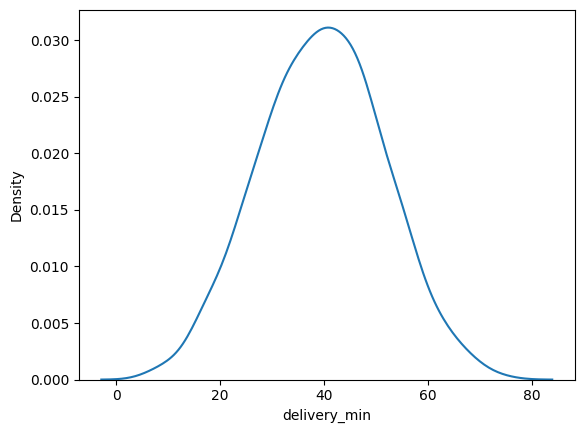

In [153]:
sns.kdeplot(y_train)
plt.show()
# hence normal

In [154]:
# linear regression using sklearn

from sklearn.linear_model import LinearRegression

In [155]:
lr = LinearRegression()
lr.fit(X_train,y_train)

y_train_predict = lr.predict(X_train)
y_test_predict = lr.predict(X_test)

In [156]:
print('R2 Score of train: ',r2_score(y_train,y_train_predict))
print('R2 Score of test: ',r2_score(y_test,y_test_predict))

R2 Score of train:  0.8875452452364204
R2 Score of test:  0.8721945866573451


In [157]:
# OLS Estimator
Xtr = np.c_[np.ones(len(X_train)), X_train.to_numpy()]
Xte = np.c_[np.ones(len(X_test)),  X_test.to_numpy()]
ytr = y_train.to_numpy()

b = np.linalg.solve(Xtr.T @ Xtr, Xtr.T @ ytr)

y_train_predict = Xtr @ b
y_test_predict  = Xte @ b

print('R2 Score of train: ', r2_score(y_train, y_train_predict))
print('R2 Score of test: ',  r2_score(y_test,  y_test_predict))

R2 Score of train:  0.8875452452364204
R2 Score of test:  0.8721945866573451


In [160]:
# gradient descent solution

learn = 0.01
epochs = 1000
# b_new = b_old - learn* dL/db

b = [np.random.randn() for _ in range(len(Xtr[0]))]

def gradient_descent(X, y, learn, epochs, b):
    n = len(y)
    for e in range(epochs):
        err = y - X @ b
        b = b + learn * (2/n) * X.T @ err
    return b



b = gradient_descent(Xtr,ytr,learn,epochs,b)


y_train_predict = Xtr @ b
y_test_predict  = Xte @ b

print('R2 Score of train: ', r2_score(y_train, y_train_predict))
print('R2 Score of test: ',  r2_score(y_test,  y_test_predict))
        

R2 Score of train:  0.8874833012384452
R2 Score of test:  0.8710389114216647
